In [2]:
def cooper_et_al(B_s, P, rho, nu, Xi, R):
    # erg s-1 Hz-1
    
    return 6e31 * (B/1e11)**2 * (P/1e-1)**(5/2) * (rho/1e7)**(-1) * (Xi/10)**(-5/2) * (R/1e6)**(-6) 

def lu_et_al(B, nu, rho):
    # erg s-1 Hz-1
    
    return (2e47/nu) * min((rho/1e6)**2, (B/1e16) * (rho/1e6)**(4/3) * (nu/1e9)**(-2/3))

# def wadiasingh_et_al()

print(lu_et_al(1e13, 1e9, 1e6))



2e+35


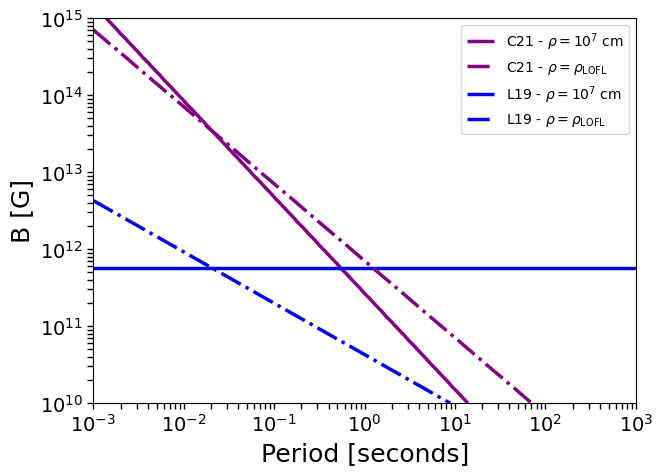

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.cbook as cbook
import matplotlib.colors as colors

def rho_polar_cap(P,R_NS):
    
    return ((R_NS * 3e10 * P)/(2 * np.pi))**(1/2)

P_arr = np.logspace(-3,3)
B_arr = np.logspace(10,15)

X, Y = np.meshgrid(P_arr,B_arr)

Z = np.zeros((len(P_arr),len(B_arr)))
Z2 = np.zeros((len(P_arr),len(B_arr)))
Z3 = np.zeros((len(P_arr),len(B_arr)))
Z4 = np.zeros((len(P_arr),len(B_arr)))
Z5 = np.zeros((len(P_arr),len(B_arr)))
Z6 = np.zeros((len(P_arr),len(B_arr)))


for i,P in enumerate(P_arr):
    for j,B in enumerate(B_arr):
        Z[i,j] = cooper_et_al(B, P, 1e7, 1.4e9, 10., 1e6)
        Z2[i,j] = lu_et_al(B, 1.4e9, 1e7)
#         Z5[i,j] = cooper_et_al(B, P, 1e8, 1.4e9, 10., 1e6)
#         Z6[i,j] = lu_et_al(B, 1.4e9, 1e8)
        
        
        
        rho_last_open = rho_polar_cap(P,1e6)
        Z3[i,j] = cooper_et_al(B, P, rho_last_open, 1.4e9, 10., 1e6)
        Z4[i,j] = lu_et_al(B, 1.4e9, rho_last_open)
        
        

fig, ax = plt.subplots(figsize=[7, 5])
ax.set_yscale('log')
ax.set_xscale('log')

ax.set_xlim(min(P_arr),max(P_arr))
ax.set_ylim(min(B_arr),max(B_arr))

# cmap = plt.get_cmap('Wistia')
# plt.set_cmap(cmap)

# plt.pcolormesh(X,Y, Z2[:,:].T, norm=colors.LogNorm(), shading='auto')
# cb = plt.colorbar()

# cb.set_label(label=r'$L_{\rm e^+e^-, CR}/L_{\rm diss, pl}$', size=18, weight='bold')
# cb.ax.tick_params(labelsize='large')

cooper = plt.contour(X,Y, (Z[:,:].T), [1.38e35],linewidths=2.5,colors='purple',linestyles='-')
lu = plt.contour(X,Y, (Z2[:,:].T), [1.38e35],linewidths=2.5,colors='blue',linestyles='-')
cooper_open = plt.contour(X,Y, (Z3[:,:].T), [1.38e35],linewidths=2.5,colors='purple',linestyles='-.')
lu_open = plt.contour(X,Y, (Z4[:,:].T), [1.38e35],linewidths=2.5,colors='blue',linestyles='-.')
# cooper_8 = plt.contour(X,Y, (Z5[:,:].T), [1.28e35],linewidths=2.,colors='purple',linestyles='dotted')
# lu_8 = plt.contour(X,Y, (Z6[:,:].T), [1.28e35],linewidths=2.5,colors='orange',linestyles='dotted')

h1,_ = cooper.legend_elements()
h2,_ = lu.legend_elements()
h3,_ = cooper_open.legend_elements()
h4,_ = lu_open.legend_elements()
# h5,_ = cooper_8.legend_elements()
# h6,_ = lu_8.legend_elements()


plt.legend([h1[0], h3[0],  h2[0],h4[0]], [r'C21 - $\rho = 10^7$ cm', r'C21 - $\rho = \rho_{\rm LOFL}$',r'L19 - $\rho = 10^7$ cm',r'L19 - $\rho = \rho_{\rm LOFL}$'],fontsize=10)

# plt.legend()
         
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=14)
ax.tick_params(direction='out', length=4, width=1, colors='k', which='both')
ax.set_xlabel(r'Period [seconds]', fontsize=18)
ax.set_ylabel(r'B [G]', fontsize=18)


plt.savefig('max_luminosities.pdf',dpi=400,bbox_inches='tight')